# Lucrare de laborator: Realizarea unui generator de text caracter-cu-caracter cu LSTM

## 1. Scopul lucrării

Construim un model care primește o secvență de caractere și estimează caracterul următor. După antrenare, folosim predicțiile pentru a genera text.

## 2. Obiective

- Explorăm și curățăm un corpus în limba engleză/română.
- Transformăm caracterele în numere și construim exemple de antrenare.
- Înțelegem rolul unui strat LSTM într-o problemă secvențială.
- Antrenăm, analizăm și folosim modelul la temperaturi diferite.


## 3. Noțiuni teoretice

### Generarea caracter-cu-caracter

Modelul construiește textul câte un caracter. De exemplu, după `hello worl`, încearcă să prezică `d`. Repetând predicția, poate continua textul.

### Ideea intuitivă din spatele LSTM

Un LSTM este o rețea recurentă cu o memorie care se actualizează pe măsură ce citește caracterele. Porțile sale decid ce informație să uite, ce informație nouă să păstreze și ce informație să folosească pentru predicția curentă. Tehnic, starea celulei (`cell state`) poartă informație de-a lungul secvenței, iar starea ascunsă (`hidden state`) rezumă contextul folosit la pasul curent. Porțile de intrare, uitare și ieșire controlează aceste actualizări.

Această memorie ajută la surprinderea unor tipare care se întind pe mai multe caractere, cum ar fi fragmente de cuvinte, spații și punctuație. Modelul învață tipare statistice; nu înțelege textul în sens uman.

### Fluxul lucrării

`text → curățare → vocabular → secvențe → numere → LSTM → predicție → text generat`

Fiecare exemplu de antrenare conține o secvență de intrare `X` și caracterul imediat următor, ținta `y`.


## 4. Importul bibliotecilor și reproducibilitate



In [1]:
from pathlib import Path
import re, html, unicodedata
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display, HTML
SEED=42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:",tf.__version__)
print("Seed folosit:",SEED)


TensorFlow: 2.21.0
Seed folosit: 42


## 5. Încărcarea corpusului

**Ce facem?** Căutăm `corpus.txt` în directorul curent al notebook-ului și îl citim ca UTF-8.  
**De ce?** Toate etapele următoare depind de textul efectiv din acest fișier.  
**Rezultat așteptat:** un fragment de text și statistici inițiale. Dacă fișierul lipsește, mesajul indică unde trebuie pus.


In [2]:
corpus_path=Path.cwd()/"corpus_ro.txt"
if not corpus_path.is_file(): raise FileNotFoundError(f"Nu am găsit {corpus_path}. Plasează corpus_ro.txt lângă notebook.")
raw_text=corpus_path.read_text(encoding="utf-8")
print("Fragment (max. 500 caractere):\n",raw_text[:500])
print(f"\nCaractere: {len(raw_text):,}; linii: {len(raw_text.splitlines()):,}; cuvinte: {len(raw_text.split()):,}; distincte: {len(set(raw_text)):,}")


Fragment (max. 500 caractere):
 Această carte a fost scrisă la epoce deosebite. Partea întâia
a văzut lumina într'un ceas când simțiam că răsboiul se apropia
de hotarele noastre și, știind în ce parte ne vom hotărî, am
pregătit o serie de schițe ușoare pentru a fi trimise în Anglia
când ne vom fi declarat aliații ei.

România e puțin cunoscută marii Împărății de peste mări,
și doriam să fie condeiul mieu acela care va vădi unele din
frumusețile ei țerii mele de naștere. Cu intenție nu am pomenit
în volumul întâiu nume, cu inte

Caractere: 279,742; linii: 6,011; cuvinte: 47,032; distincte: 88


## 6. Explorarea și curățarea textului

**Ce facem?** Verificăm cuvintele despărțite cu cratimă la capăt de rând, apoi unificăm newline-urile simple în spații și păstrăm `\n\n` între paragrafe.  
**De ce?** Rândurile rupte artificial nu trebuie învățate ca întreruperi de text, iar pauzele dintre paragrafe păstrează structura. Cratimele se inspectează ca să nu stricăm cuvinte.

Nu ștergem punctuația. În acest corpus, `--` la capăt de rând este punctuație, nu cuvânt despărțit.


In [3]:
# Normalizăm newline-urile, apoi inspectăm formele literă-cratimă-newline-literă.
normalized_lines=raw_text.replace("\r\n","\n").replace("\r","\n")
hyphen_pattern=re.compile(r"(?u)([^\W\d_]+)-\n([^\W\d_]+)")
hyphenated_word_breaks=hyphen_pattern.findall(normalized_lines)
print(f"Posibile cuvinte despărțite cu cratimă: {len(hyphenated_word_breaks)}")
for left,right in hyphenated_word_breaks[:20]: print(f"Verifică manual: {left}-\n{right}")
if not hyphenated_word_breaks: print("Nu s-au găsit; secvențele -- sunt punctuație și se păstrează.")
def clean_corpus(text):
    """Unește newline-urile simple cu spațiu și păstrează separatorii de paragraf."""
    text=text.replace("\r\n","\n").replace("\r","\n")
    text="\n".join(line.strip() for line in text.split("\n"))
    text=re.sub(r"\n{3,}","\n\n",text)
    return re.sub(r"(?<!\n)\n(?!\n)"," ",text).strip()
clean_text=clean_corpus(normalized_lines)
def corpus_statistics(text):
    words=text.split()
    return {"caractere":len(text),"caractere_unice":len(set(text)),"cuvinte":len(words),"linii":len(text.splitlines()),"lungime_medie_cuvant":sum(map(len,words))/len(words) if words else 0,"pauze_paragraf":text.count("\n\n")}
print("Înainte:",corpus_statistics(raw_text)); print("După:",corpus_statistics(clean_text))
print("Fragment curățat:\n",clean_text[:500])
if len(clean_text)<2: raise ValueError("Corpusul este prea scurt după curățare.")


Posibile cuvinte despărțite cu cratimă: 0
Nu s-au găsit; secvențele -- sunt punctuație și se păstrează.
Înainte: {'caractere': 279742, 'caractere_unice': 88, 'cuvinte': 47032, 'linii': 6011, 'lungime_medie_cuvant': 4.886183874808641, 'pauze_paragraf': 1050}
După: {'caractere': 279205, 'caractere_unice': 88, 'cuvinte': 47032, 'linii': 2071, 'lungime_medie_cuvant': 4.886183874808641, 'pauze_paragraf': 1035}
Fragment curățat:
 Această carte a fost scrisă la epoce deosebite. Partea întâia a văzut lumina într'un ceas când simțiam că răsboiul se apropia de hotarele noastre și, știind în ce parte ne vom hotărî, am pregătit o serie de schițe ușoare pentru a fi trimise în Anglia când ne vom fi declarat aliații ei.

România e puțin cunoscută marii Împărății de peste mări, și doriam să fie condeiul mieu acela care va vădi unele din frumusețile ei țerii mele de naștere. Cu intenție nu am pomenit în volumul întâiu nume, cu inte


### Grafic: efectul unificării rândurilor

**Ce facem?** Comparăm numărul de caractere, linii și pauze de paragraf înainte și după. Graficul arată efectul curățării; cifrele concrete și concluzia apar sub el.


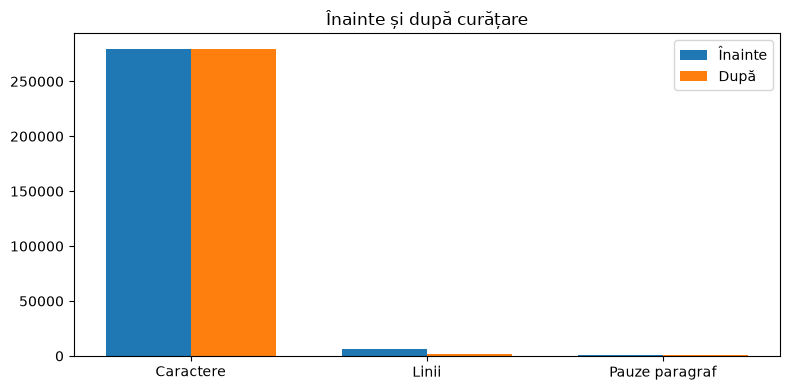

Caractere 279,742 → 279,205; linii 6,011 → 2,071; pauze păstrate 1,035.
Concluzie: rândurile simple devin spații, iar paragrafele rămân separate.


In [4]:
b=corpus_statistics(raw_text); a=corpus_statistics(clean_text)
labels=["Caractere","Linii","Pauze paragraf"]; old=[b["caractere"],b["linii"],b["pauze_paragraf"]]; new=[a["caractere"],a["linii"],a["pauze_paragraf"]]
x=np.arange(3); w=.36; fig,ax=plt.subplots(figsize=(8,4))
ax.bar(x-w/2,old,w,label="Înainte"); ax.bar(x+w/2,new,w,label="După"); ax.set_xticks(x,labels); ax.set_title("Înainte și după curățare"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Caractere {b['caractere']:,} → {a['caractere']:,}; linii {b['linii']:,} → {a['linii']:,}; pauze păstrate {a['pauze_paragraf']:,}.")
print("Concluzie: rândurile simple devin spații, iar paragrafele rămân separate.")


## 7. Statistici și frecvența caracterelor

**Ce facem?** Măsurăm caracteristicile corpusului și numărăm aparițiile fiecărui caracter.  
**De ce?** Frecvențele ne arată ce caractere întâlnește cel mai des modelul și câtă diversitate trebuie să învețe.


In [5]:
stats = corpus_statistics(clean_text)
character_counts = Counter(clean_text)
most_common_characters = character_counts.most_common(15)

print(f"Număr total de caractere: {stats['caractere']:,}")
print(f"Număr de caractere unice: {stats['caractere_unice']:,}")
print(f"Număr de cuvinte: {stats['cuvinte']:,}")
print(f"Număr de linii: {stats['linii']:,}")
print(f"Lungimea medie a cuvântului: {stats['lungime_medie_cuvant']:.2f}")
print("\nCele mai frecvente caractere:")
for character, count in most_common_characters:
    printable = repr(character)
    print(f"{printable:8} {count:8,} ({count / len(clean_text):.2%})")

Număr total de caractere: 279,205
Număr de caractere unice: 88
Număr de cuvinte: 47,032
Număr de linii: 2,071
Lungimea medie a cuvântului: 4.89

Cele mai frecvente caractere:
' '        47,328 (16.95%)
'e'        25,517 (9.14%)
'i'        21,786 (7.80%)
'a'        20,145 (7.22%)
'r'        16,487 (5.90%)
'u'        14,357 (5.14%)
'n'        14,195 (5.08%)
't'        12,734 (4.56%)
'c'        11,650 (4.17%)
'l'        10,247 (3.67%)
'ă'         9,896 (3.54%)
's'         8,783 (3.15%)
'o'         8,558 (3.07%)
'd'         7,857 (2.81%)
'm'         7,007 (2.51%)


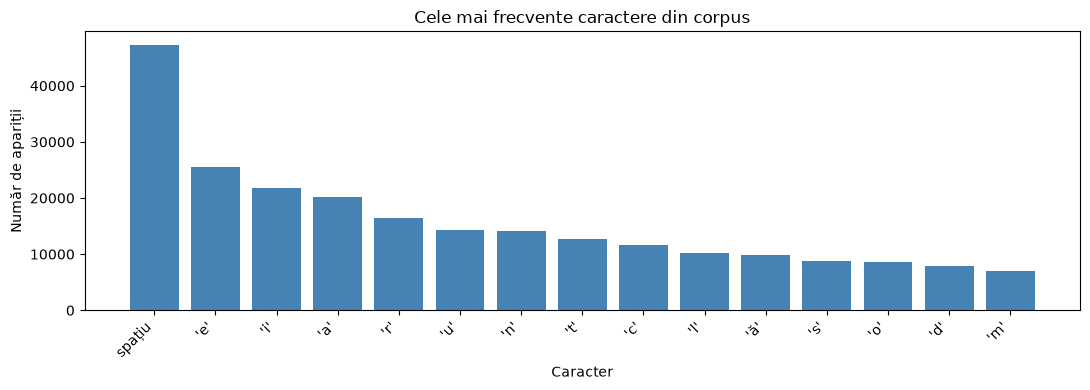

Cel mai frecvent: ' ' — 47,328 (16.95%).
Spațiu: 47,328 (16.95%); total 279,205 caractere.


In [ ]:
labels = ["spațiu" if char == " " else "rând nou" if char == "\n" else repr(char) for char, _ in most_common_characters]
values = [count for _, count in most_common_characters]
plt.figure(figsize=(11, 4))
plt.bar(labels, values, color="steelblue")
plt.title("Cele mai frecvente caractere din corpus")
plt.xlabel("Caracter")
plt.ylabel("Număr de apariții")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
most_common_character,maximum_frequency=character_counts.most_common(1)[0]
space_frequency=character_counts.get(" ",0)
print(f"Spațiu: {space_frequency:,} ({space_frequency/len(clean_text):.2%}); total {len(clean_text):,} caractere.")

## 8. Vocabularul și codificarea caracterelor

**Ce facem?** Asociem fiecărui caracter un indice întreg și păstrăm conversia inversă.  
**De ce?** Rețeaua operează pe numere, nu pe caractere textuale. Indicii sunt etichete pentru clase, nu măsuri ale distanței dintre caractere.


In [7]:
unique_characters = sorted(set(clean_text))
character_to_index = {character: index for index, character in enumerate(unique_characters)}
index_to_character = {index: character for character, index in character_to_index.items()}
vocabulary_size = len(unique_characters)

print("Dimensiunea vocabularului:", vocabulary_size)
print("Primele caractere și indicii lor:")
for character in unique_characters[:20]:
    print(f"{repr(character):8} → {character_to_index[character]}")

example_text = clean_text[:20]
example_indices = [character_to_index[character] for character in example_text]
print("\nExemplu text:   ", repr(example_text))
print("Indici:         ", example_indices)
print("Decodificare:   ", "".join(index_to_character[i] for i in example_indices))

Dimensiunea vocabularului: 88
Primele caractere și indicii lor:
'\n'     → 0
' '      → 1
'!'      → 2
"'"      → 3
'('      → 4
')'      → 5
'*'      → 6
','      → 7
'-'      → 8
'.'      → 9
'0'      → 10
'1'      → 11
'2'      → 12
'3'      → 13
'4'      → 14
'5'      → 15
'6'      → 16
'7'      → 17
'8'      → 18
'9'      → 19

Exemplu text:    'Această carte a fost'
Indici:          [23, 49, 51, 47, 64, 65, 83, 1, 49, 47, 63, 65, 51, 1, 47, 1, 52, 61, 64, 65]
Decodificare:    Această carte a fost


## 9. Construirea secvențelor de antrenare

**Ce facem?** Pentru fiecare fereastră de `sequence_length` caractere, folosim caracterul imediat următor drept țintă.  
**De ce?** Astfel modelul învață sarcina repetată „având contextul acesta, ce caracter urmează?”.

De exemplu, intrarea `hello worl` are ca țintă `d`. `X` reprezintă contextul, iar `y` este indicele caracterului următor. Lungimea secvenței este ajustată automat dacă textul este mai scurt decât valoarea aleasă.


In [8]:
sequence_length = min(100, len(clean_text) - 1)
MAX_TEXT_LENGTH = None  
model_text = clean_text if MAX_TEXT_LENGTH is None else clean_text[:MAX_TEXT_LENGTH]

if len(model_text) <= sequence_length:
    raise ValueError("Textul selectat este prea scurt pentru sequence_length. Mărește corpusul sau redu lungimea secvenței.")

encoded_text = np.fromiter((character_to_index[ch] for ch in model_text), dtype=np.int32)
number_of_examples = len(encoded_text) - sequence_length

print(f"Lungimea secvenței: {sequence_length}")
print(f"Caractere folosite la antrenare: {len(model_text):,}")
print(f"Perechi secvență-țintă: {number_of_examples:,}")

for start in range(min(3, number_of_examples)):
    input_text = "".join(index_to_character[i] for i in encoded_text[start:start + sequence_length])
    target_character = index_to_character[int(encoded_text[start + sequence_length])]
    print(f"\nInput:  {input_text!r}")
    print(f"Target: {target_character!r}")

Lungimea secvenței: 100
Caractere folosite la antrenare: 279,205
Perechi secvență-țintă: 279,105

Input:  "Această carte a fost scrisă la epoce deosebite. Partea întâia a văzut lumina într'un ceas când simți"
Target: 'a'

Input:  "ceastă carte a fost scrisă la epoce deosebite. Partea întâia a văzut lumina într'un ceas când simția"
Target: 'm'

Input:  "eastă carte a fost scrisă la epoce deosebite. Partea întâia a văzut lumina într'un ceas când simțiam"
Target: ' '


## 10. Pregătirea intrărilor și țintelor

**Ce facem?** 
Codul transformă șirul lung de numere encoded_text (279.205 indici) într-un set de exemple de antrenare. Fiecare exemplu conține:

X: 100 de caractere consecutive (contextul);
y: caracterul care urmează imediat după ele (ținta).

Modelul învață sarcina „dându-se aceste 100 de caractere, ce caracter urmează?".

Forma `X` este `(număr_exemple, lungime_secvență)`. Forma `y` este `(număr_exemple,)`; fiecare valoare din `y` este clasa caracterului următor.


In [9]:
training_sequences = np.lib.stride_tricks.sliding_window_view(encoded_text, sequence_length + 1)
X = training_sequences[:, :-1]
y = training_sequences[:, -1]

# Sliding window produce o vedere compactă; copiem ca să obținem un tablou stabil pentru Keras.
X = np.array(X, dtype=np.int32, copy=True)
y = np.array(y, dtype=np.int32, copy=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Tip X:", X.dtype, "| Tip y:", y.dtype)
print(f"O secvență are {X.shape[1]} caractere, iar fiecare țintă este unul dintre {vocabulary_size} indici.")

X shape: (279105, 100)
y shape: (279105,)
Tip X: int32 | Tip y: int32
O secvență are 100 caractere, iar fiecare țintă este unul dintre 88 indici.


## 11. Definirea modelului LSTM

**Ce facem?** Definim un model mic: `Embedding → LSTM → Dense`.  
**De ce?** Embedding transformă indicii în vectori învățabili, LSTM citește ordinea caracterelor și păstrează context, iar Dense produce un scor pentru fiecare caracter posibil.

Hiperparametrii sunt separați pentru a fi ușor de modificat. Dimensiunile moderate și numărul limitat de epoci fac experimentul potrivit pentru un calculator obișnuit.


In [10]:
embedding_dimension = 32
lstm_units = 128
batch_size = 128
number_of_epochs = 10
learning_rate = 0.001

model = keras.Sequential([
    keras.Input(shape=(sequence_length,), dtype="int32"),
    layers.Embedding(input_dim=vocabulary_size, output_dim=embedding_dimension),
    layers.LSTM(lstm_units),
    layers.Dense(vocabulary_size),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 32)        │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │        82,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 88)             │        11,352 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,600 (377.34 KB)

 Trainable params: 96,600 (377.34 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Compilarea modelului

`loss` măsoară cât de departe sunt predicțiile de caracterul corect. `optimizer` ajustează ponderile pentru a reduce această eroare. Problema este o clasificare multi-clasă: fiecare caracter din vocabular este o clasă posibilă. `SparseCategoricalCrossentropy` acceptă direct indicii întregi ai țintelor.


In [11]:
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
model.compile(
    optimizer=optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["sparse_categorical_accuracy"],
)
print("Model compilat.")

Model compilat.


## 13. Antrenarea

**Ce facem?** Antrenăm modelul în loturi și păstrăm istoricul metricilor.  
**De ce?** Antrenarea ajustează ponderile astfel încât caracterul corect să primească un scor mai mare. `EarlyStopping` oprește lucrul dacă loss-ul de antrenare nu se mai îmbunătățește.

Pentru simplitate, urmărim loss-ul pe datele de antrenare. Fără set separat de validare, nu putem evalua riguros generalizarea sau confirma supraînvățarea; acest lucru este discutat la analiză.


In [12]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="loss", patience=2, restore_best_weights=True
)

history = model.fit(
    X,
    y,
    batch_size=batch_size,
    epochs=number_of_epochs,
    callbacks=[early_stopping],
    verbose=1,
)

print("\nUltimele valori înregistrate:")
print(f"loss: {history.history['loss'][-1]:.4f}")
print(f"accuracy: {history.history['sparse_categorical_accuracy'][-1]:.4f}")

Epoch 1/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 345s 157ms/step - loss: 2.4111 - sparse_categorical_accuracy: 0.2974
Epoch 2/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 525s 240ms/step - loss: 2.1047 - sparse_categorical_accuracy: 0.3661
Epoch 3/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 362s 166ms/step - loss: 1.9812 - sparse_categorical_accuracy: 0.4034
Epoch 4/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 326s 149ms/step - loss: 1.8911 - sparse_categorical_accuracy: 0.4289
Epoch 5/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 329s 151ms/step - loss: 1.8211 - sparse_categorical_accuracy: 0.4483
Epoch 6/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 337s 154ms/step - loss: 1.7667 - sparse_categorical_accuracy: 0.4633
Epoch 7/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 316s 145ms/step - loss: 1.7227 - sparse_categorical_accuracy: 0.4752
Epoch 8/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 325s 149ms/step - loss: 1.6870 - sparse_categorical_accuracy: 0.4858
Epoch 9/10
2181/2181 ━━━━━━━━━━━━━━━━━━━━ 335s 154ms/step - loss: 1.6573 - sparse_categorical_accuracy: 0.4942
E

## 14. Evoluția antrenării

**Ce facem?** Reprezentăm loss-ul și acuratețea pentru fiecare epocă.  
**Interpretare:** loss-ul mai mic arată predicții mai potrivite pe exemplele de antrenare; accuracy mai mare arată că modelul ghicește mai des caracterul exact. Aceste valori nu garantează text coerent. Dacă performanța pe antrenare crește, dar pe date noi scade, aceasta poate indica supraînvățare. Aici nu avem un set de validare, deci nu tragem o astfel de concluzie doar din grafic.


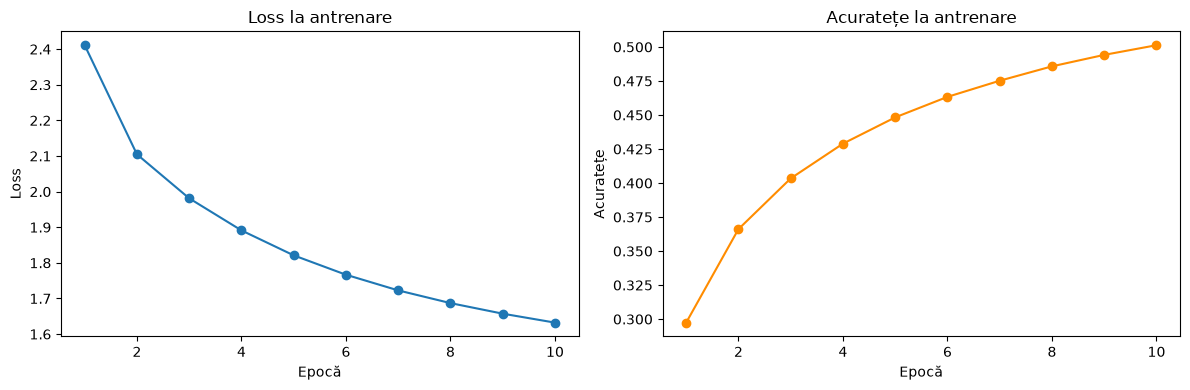

In [13]:
epochs_ran = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_ran, history.history["loss"], marker="o")
axes[0].set_title("Loss la antrenare")
axes[0].set_xlabel("Epocă")
axes[0].set_ylabel("Loss")
axes[1].plot(epochs_ran, history.history["sparse_categorical_accuracy"], marker="o", color="darkorange")
axes[1].set_title("Acuratețe la antrenare")
axes[1].set_xlabel("Epocă")
axes[1].set_ylabel("Acuratețe")
plt.tight_layout()
plt.show()

## 15. Generarea textului

**Ce facem?** Pornim de la un fragment inițial și alegem repetat următorul caracter din distribuția modelului.  
**Temperatura** modifică distribuția probabilităților: o valoare mică favorizează alegerile cu scor mare și produce text mai conservator; o valoare mai mare face alegerile mai variate și mai imprevizibile.

Funcția normalizează fragmentul inițial la lungimea cerută de model, dar păstrează textul original în rezultatul returnat. Dacă seed-ul conține caractere în afara vocabularului, ele sunt înlocuite cu un caracter cunoscut pentru contextul intern.


In [14]:
def sample_next_character(logits, temperature):
    """Alege un indice din scorurile modelului, ajustate prin temperatură."""
    if temperature <= 0:
        raise ValueError("Temperatura trebuie să fie mai mare decât zero.")
    scaled_logits = logits / temperature
    probabilities = tf.nn.softmax(scaled_logits).numpy()
    probabilities = probabilities / probabilities.sum()
    return int(np.random.choice(len(probabilities), p=probabilities))


def generate_text(seed_text, number_of_characters=300, temperature=0.8):
    """Generează caractere succesive pornind de la seed_text."""
    if not seed_text:
        raise ValueError("seed_text trebuie să conțină cel puțin un caracter.")
    if number_of_characters < 0:
        raise ValueError("number_of_characters nu poate fi negativ.")
    if temperature <= 0:
        raise ValueError("temperature trebuie să fie mai mare decât zero.")

    known_fallback = unique_characters[0]
    context = [character_to_index.get(ch, character_to_index[known_fallback]) for ch in seed_text]
    generated = seed_text

    for _ in range(number_of_characters):
        model_context = context[-sequence_length:]
        if len(model_context) < sequence_length:
            model_context = [character_to_index[known_fallback]] * (sequence_length - len(model_context)) + model_context
        input_array = np.array([model_context], dtype=np.int32)
        logits = model(input_array, training=False)[0]
        next_index = sample_next_character(logits, temperature)
        next_character = index_to_character[next_index]
        generated += next_character
        context.append(next_index)

    return generated

seed_text = "The " if "The " in clean_text else clean_text[:min(20, len(clean_text))]
print("Seed folosit:", repr(seed_text))

Seed folosit: 'Această carte a fost'


## 16. Experiment: temperaturi diferite

Generăm același număr de caractere cu temperaturi diferite. Seed-ul și modelul sunt aceleași; sampling-ul este aleator, așa că rezultatul poate varia la fiecare rulare.


In [15]:
temperatures = [0.2, 0.5, 0.8, 1.0]
for temperature in temperatures:
    sample = generate_text(seed_text, number_of_characters=250, temperature=temperature)
    print(f"\n--- temperature = {temperature} ---\n")
    print(sample)


--- temperature = 0.2 ---

Această carte a fost în aceste prin care a fost de aceste prin de care lumina aceste mici de prin care a fost de care a fost de aceste prin cele de aceste care se poate cu aceste prin cele mai mi sunt alte lumina de lumina de aceste care a fost de prin care a fost între

--- temperature = 0.5 ---

Această carte a fost de altă ameniștea cu sunt privind aduce am altane de părea de vreme cele în mijloare să cei la mai mult o nu mai viseri a fi scumpe în care cele roșterile de aceste care pe care a prea aproase să plate în aceia potoarele asupra de luminate de lemnul

--- temperature = 0.8 ---

Această carte a fost o străpătul. A fot peste li suțnită ce în poarte lumine ara de fom, ciudată în iubire a care tot ca mai mai pati. Îmi se mijloc denioase de face.

Reasuri de o îndeninanesc nă lămărată mai lume la afia a întorc o găsărița pot sfinți din de dor înnăp

--- temperature = 1.0 ---

Această carte a fost încetulea de aminti, alta să poate, descopeată păreau 

### Observarea exemplelor generate

Compară rezultatele afișate chiar deasupra. Verifică dacă la temperaturi mici apar repetiții sau alegeri previzibile și dacă temperaturile mai mari aduc varietate ori mai mult zgomot. Efectul exact depinde de corpus și de antrenare; nu există o temperatură optimă universală.
